In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

df = pd.read_csv(r"C:\Users\Gustavo\Documents\Irma\Ironhack\SEMANA 5\DAY 1\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
df.shape

(2443651, 9)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [13]:
# Frequency table for 'category'
frequency_table = df['category'].value_counts()

# Calculating the proportion of each unique value in the 'category'
proportion_table = df['category'].value_counts(normalize=True)

frequency_table, proportion_table

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
                                            ...  
 Motorbike Chassis                            107
 Alexa Built-In Devices                       107
 Plugs                                        107
 Smart Home Security & Lighting               104
 Smart Speakers                                54
 Name: count, Length: 296, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Motorbike Chassis                         0.000044
 Alexa Built-In Devices  

In [15]:
# Top 5

top5= pd.DataFrame({"count": frequency_table.head(5), "proportion": proportion_table.head(5)})

print("Top 5 categories:")
display(top5)

Top 5 categories:


,count,proportion
category,,
Sports & Outdoors,836265,0.342219
Beauty,19312,0.007903
"Handmade Clothing, Shoes & Accessories",19229,0.007869
Bath & Body,19092,0.007813
Birthday Gifts,18978,0.007766


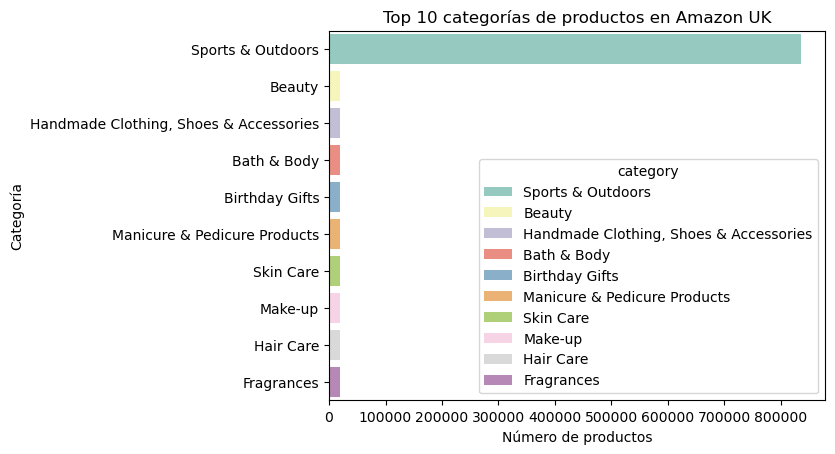

In [19]:
frequency_table = df['category'].value_counts().head(10)

ax = sns.barplot(
    y=frequency_table.index,
    x=frequency_table.values,
    palette="Set3",
    hue=frequency_table.index,
    legend=True
)

sns.move_legend(ax, "lower right")
plt.title("Top 10 categorías de productos en Amazon UK")
plt.xlabel("Número de productos")
plt.ylabel("Categoría")
plt.show()

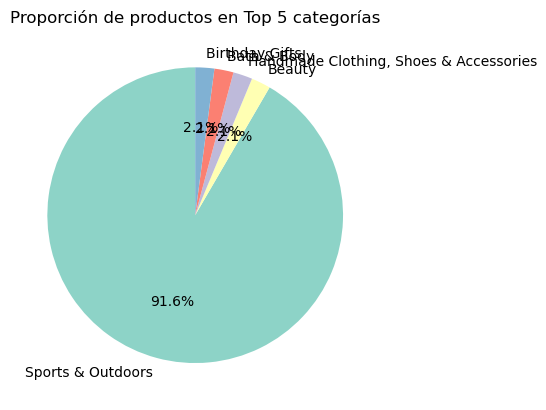

In [20]:
#  Top 5 categories
top5 = df['category'].value_counts().head(5)

top5.plot.pie(
    autopct='%.1f%%',       
    startangle=90,           
    colors=sns.color_palette("Set3") 
)

plt.title("Proporción de productos en Top 5 categorías")
plt.ylabel("")
plt.show()


In [ ]:
# What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency? The frequency analysis shows that Sports & Outdoors overwhelmingly dominates Amazon UK listings, accounting for more than 90% of all products.
# The other top categories (Beauty, Handmade Clothing, Bath & Body, and Birthday Gifts) each represent only about 2–3% of the listings.
# The bar chart highlights the large difference in scale between Sports & Outdoors and other categories, while the pie chart confirms that a single category dominates the marketplace.
# Business insight: This concentration suggests that most listings in the dataset are related to sports and outdoor products. Businesses entering this market should be aware of the strong competition in this segment, while other categories may represent niche opportunities.

In [21]:
# --- Part 2: Product Pricing ---

# Central tendency
price = df['price'].dropna()
price_mean = price.mean()
price_median = price.median()
price_mode = price.mode().iloc[0] if not price.mode().empty else None

print("Mean price:", round(price_mean, 2))
print("Median price:", round(price_median, 2))
print("Mode price:", round(price_mode, 2))

Mean price: 89.24
Median price: 19.09
Mode price: 9.99


In [22]:
# Dispersion
price_var = price.var()
price_std = price.std()
price_min = price.min()
price_max = price.max()
price_range = price_max - price_min
price_q1 = price.quantile(0.25)
price_q3 = price.quantile(0.75)
price_iqr = price_q3 - price_q1

print("Variance:", round(price_var, 2))
print("Standard Deviation:", round(price_std, 2))
print("Min:", price_min)
print("Q1:", price_q1)
print("Median:", price_median)
print("Q3:", price_q3)
print("Max:", price_max)
print("Range:", price_range)
print("IQR:", price_iqr)


Variance: 119445.49
Standard Deviation: 345.61
Min: 0.0
Q1: 9.99
Median: 19.09
Q3: 45.99
Max: 100000.0
Range: 100000.0
IQR: 36.0


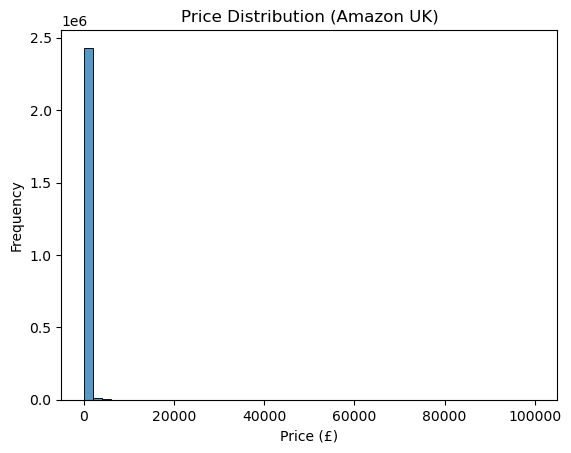

In [24]:
sns.histplot(price, bins=50, kde=False)
plt.title("Price Distribution (Amazon UK)")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")
plt.show()


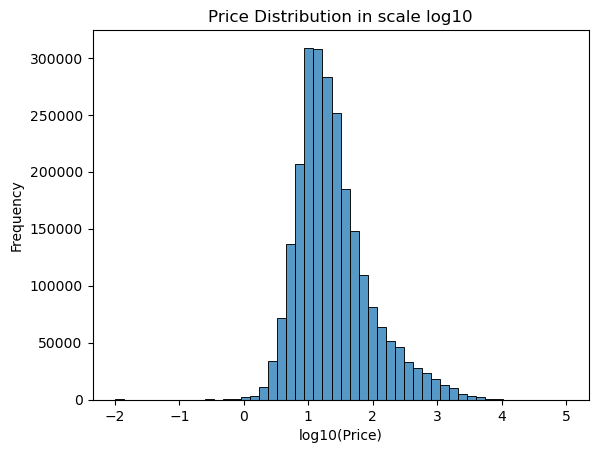

In [26]:
sns.histplot(np.log10(price[price > 0]), bins=50, kde=False)
plt.title("Price Distribution in scale log10")
plt.xlabel("log10(Price)")
plt.ylabel("Frequency")
plt.show()

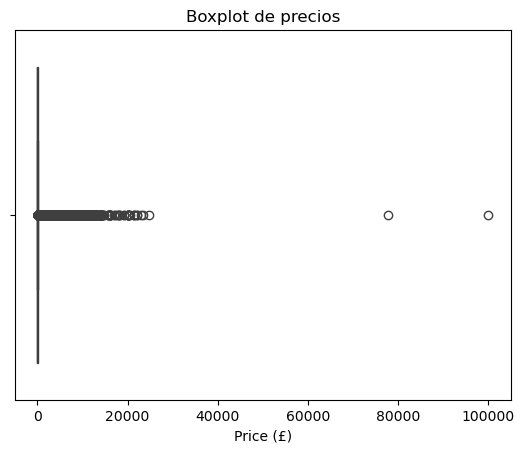

In [27]:
sns.boxplot(x=price)
plt.title("Boxplot de precios")
plt.xlabel("Price (£)")
plt.show()

In [ ]:
# The average product price is £89.24, but the median (£19.09) and mode (£9.99) are much lower.
# This indicates a highly skewed distribution, where a few very expensive items (up to £100,000) inflate the mean.
# The interquartile range (IQR) is £36, which shows that most products are concentrated between £9.99 and £45.99.
# The histogram confirms that the majority of products fall within the lower price range, while the log-transformed histogram and the boxplot reveal the presence of extreme outliers.

#Business insight: Pricing on Amazon UK is dominated by low-cost items, but a small number of premium products create a long right tail. 
#Companies should be cautious when using averages for pricing strategies, as the median and mode provide a better representation of the “typical” price point.

In [29]:
# Part 3
# --- Centrality ---
rating = df['stars'].dropna() 

rating_mean = rating.mean()
rating_median = rating.median()
rating_mode = rating.mode().iloc[0] if not rating.mode().empty else np.nan

print("Mean rating:", round(rating_mean, 2))
print("Median rating:", rating_median)
print("Mode rating:", rating_mode)

Mean rating: 2.15
Median rating: 0.0
Mode rating: 0.0


In [31]:
# --- Dispersion ---
rating_var = rating.var()
rating_std = rating.std()
rating_q1 = rating.quantile(0.25)
rating_q3 = rating.quantile(0.75)
rating_iqr = rating_q3 - rating_q1

print("\nVariance:", round(rating_var, 2))
print("Standard Deviation:", round(rating_std, 2))
print("Q1:", rating_q1)
print("Q3:", rating_q3)
print("IQR:", rating_iqr)


Variance: 4.82
Standard Deviation: 2.19
Q1: 0.0
Q3: 4.4
IQR: 4.4


In [32]:
# --- Shape of distribution ---
rating_skew = rating.skew()
rating_kurt = rating.kurt()

print("\nSkewness:", round(rating_skew, 2))
print("Kurtosis:", round(rating_kurt, 2))


Skewness: 0.08
Kurtosis: -1.93


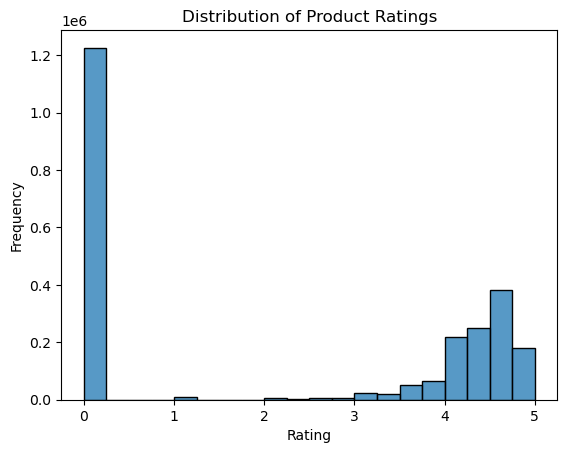

In [33]:
# --- Visualization ---
sns.histplot(rating, bins=20, kde=False)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

In [ ]:
#The analysis of product ratings shows two clear groups:

#A very large share of products with rating = 0, which likely indicates items without customer reviews.

#Among products with reviews, most ratings are concentrated between 4 and 5, reflecting generally positive customer feedback.

#The mean rating is 2.15, but the median and mode are both 0 due to the large number of unrated products. This makes the mean not very representative of actual customer opinions.

#Business insight: Companies should be careful when interpreting ratings in aggregate, since many items lack reviews. 

#For items with ratings, the positive skew towards high scores can be leveraged in marketing, but the absence of reviews suggests that encouraging customer feedback could be a valuable strategy.